# REPD — Project Pipeline Sankey (last 2 years)

How UK renewable projects moved through the planning pipeline over the two years before the latest REPD update.

**Cohort:** any project with a stage date (submitted, granted, refused, withdrawn, appeal refused/withdrawn, under construction, operational) in the window. The expiry date isn't used to select projects because it is often a scheduled deadline rather than an event.
Each project is placed on a path from its current `Development Status (short)`; earlier stages are assumed even when a date is missing.

**Excluded statuses:** Revised, Decommissioned, No Application Required, Appeal Lodged.

**Reading the chart:** the x-axis is time, and each stage sits at the cumulative mean months from submission, so a longer ribbon means a longer step. Labels give mean ± SD and median months. Timings use only projects with both dates; see `n` in the table.

In [1]:
from pathlib import Path

import pandas as pd
from repd.processor import REPDProcessor
from repd.visualise import plot_time_sankey

REPD_CSV = Path("../data/REPD_Publication_Q2_2026.csv")

## 1. Load and build the cohort

In [2]:
processor = REPDProcessor(REPD_CSV, encoding="latin-1")
df = processor.convert_datetime(processor.load())

# Anchor the window to the data's latest update, not today, so the cohort is stable per publication.
end = df["Record Last Updated (dd/mm/yyyy)"].max()
start = end - pd.DateOffset(years=2)

STAGE_DATES = [
    "Planning Application Submitted", "Planning Permission Granted",
    "Planning Permission Refused", "Planning Application Withdrawn",
    "Appeal Refused", "Appeal Withdrawn", "Under Construction", "Operational",
]  # not "Planning Permission Expired": it's often a future deadline, not a stage reached

# Path of nodes each final status flows through. Order = left to right.
PATHS = {
    "Application Submitted":       ["Submitted", "Still in planning"],
    "Application Refused":         ["Submitted", "Refused"],
    "Appeal Refused":              ["Submitted", "Refused"],
    "Application Withdrawn":       ["Submitted", "Withdrawn"],
    "Appeal Withdrawn":            ["Submitted", "Withdrawn"],
    "Awaiting Construction":       ["Submitted", "Granted", "Awaiting construction"],
    "Planning Permission Expired": ["Submitted", "Granted", "Expired / abandoned"],
    "Abandoned":                   ["Submitted", "Granted", "Expired / abandoned"],
    "Under Construction":          ["Submitted", "Granted", "Under construction", "Still building"],
    "Operational":                 ["Submitted", "Granted", "Under construction", "Operational"],
}

in_window = df[STAGE_DATES].apply(lambda c: c.between(start, end)).any(axis=1)
cohort = df[in_window & df["Development Status (short)"].isin(PATHS)].copy()

print(f"Window: {start:%d %b %Y} → {end:%d %b %Y}")
print(f"Cohort: {len(cohort):,} projects")
cohort["Development Status (short)"].value_counts()

Window: 24 Jul 2024 → 24 Jul 2026
Cohort: 4,188 projects


Development Status (short)
Awaiting Construction    2547
Application Submitted    1052
Application Refused       241
Under Construction        129
Application Withdrawn     119
Operational                95
Appeal Refused              2
Abandoned                   2
Appeal Withdrawn            1
Name: count, dtype: int64

## 2. Stage durations (months)

In [3]:
# Which pair of date columns measures the time spent on each link.
LINK_DATES = {
    ("Submitted", "Granted"):                    ("Planning Application Submitted", "Planning Permission Granted"),
    ("Submitted", "Refused"):                    ("Planning Application Submitted", "Planning Permission Refused"),
    ("Submitted", "Withdrawn"):                  ("Planning Application Submitted", "Planning Application Withdrawn"),
    ("Submitted", "Still in planning"):          ("Planning Application Submitted", None),  # time waiting so far
    ("Granted", "Awaiting construction"):        ("Planning Permission Granted", None),
    ("Granted", "Expired / abandoned"):          ("Planning Permission Granted", "Planning Permission Expired"),
    ("Granted", "Under construction"):           ("Planning Permission Granted", "Under Construction"),
    ("Under construction", "Still building"):    ("Under Construction", None),
    ("Under construction", "Operational"):       ("Under Construction", "Operational"),
}


def months(rows: pd.DataFrame, a: str, b: str | None) -> pd.Series:
    """Mean/SD/median/n of months from date column a to b (b=None → to the window end)."""
    to = rows[b] if b else end
    m = ((to - rows[a]).dt.days / 30.44).dropna()
    m = m[m >= 0]  # drop data-entry errors where the later stage predates the earlier
    return pd.Series({"n": len(m), "mean": m.mean(), "sd": m.std(), "median": m.median()})


# One row per (project, link).
links = (
    cohort.assign(path=cohort["Development Status (short)"].map(PATHS))
    .assign(pair=lambda d: d["path"].map(lambda p: list(zip(p, p[1:]))))
    .explode("pair")
)

stats = pd.DataFrame(
    {pair: {"projects": len(g), **months(g, *LINK_DATES[pair])} for pair, g in links.groupby("pair")}
).T
stats.index.names = ["from", "to"]
stats = stats.astype({"projects": int, "n": int}).round(1)
stats["open"] = [LINK_DATES[pair][1] is None for pair in stats.index]
stats

projects     n  mean    sd  median  \
from               to                                                          
Granted            Awaiting construction      2547  2533  12.5   6.5    12.4   
                   Expired / abandoned           2     0   NaN   NaN     NaN   
                   Under construction          224   162  28.5  21.0    25.0   
Submitted          Granted                    2773  2742   7.6   9.9     2.8   
                   Refused                     243   242  10.3  10.7     7.2   
                   Still in planning          1052  1052  11.2   6.4    11.8   
                   Withdrawn                   120   119   7.8   9.7     2.9   
Under construction Operational                  95    46  23.3  16.7    18.9   
                   Still building              129   128  12.3   6.1    12.7   

                                           open  
from               to                            
Granted            Awaiting construction   True  
                   Expired / abandoned    False  
                   Under construction     False  
Submitted          Granted                False  
                   Refused                False  
                   Still in planning       True  
                   Withdrawn              False  
Under construction Operational            False  
                   Still building          True

## 3. Sankey

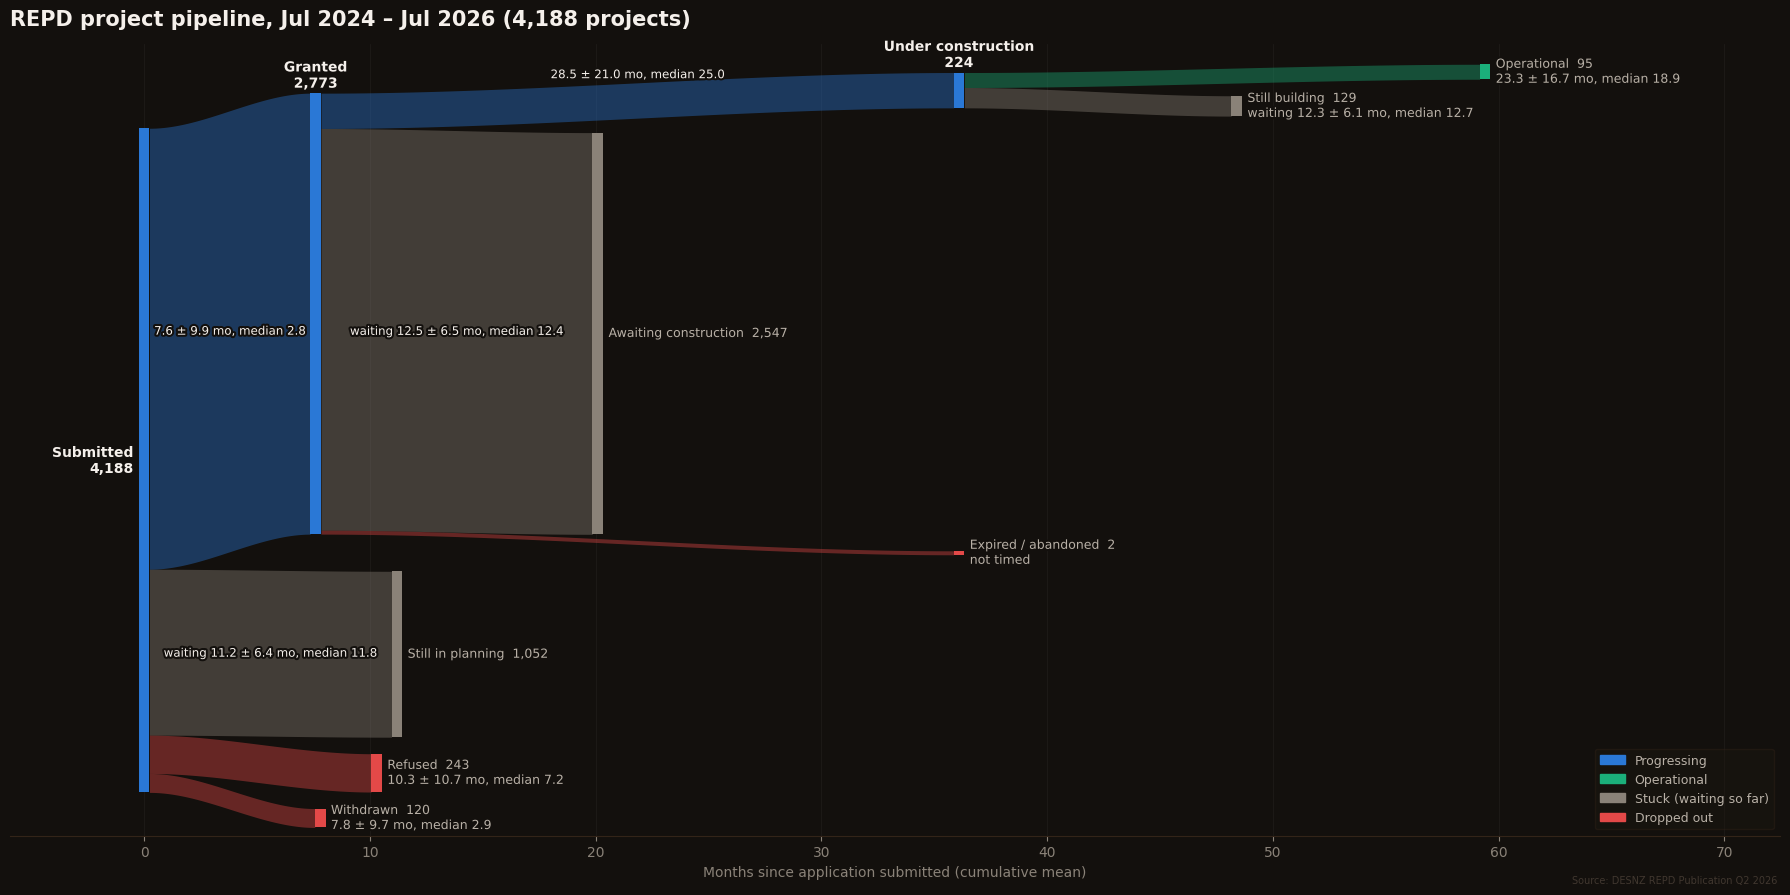

In [4]:
STUCK, DROP, FLOW, DONE = "#8a8278", "#e34948", "#2a78d6", "#1baf7a"
NODE_COLORS = {
    "Submitted": FLOW, "Granted": FLOW, "Under construction": FLOW, "Operational": DONE,
    "Refused": DROP, "Withdrawn": DROP, "Expired / abandoned": DROP,
    "Still in planning": STUCK, "Awaiting construction": STUCK, "Still building": STUCK,
}
ORDER = ["Granted", "Under construction", "Operational", "Still building", "Awaiting construction",
         "Expired / abandoned", "Still in planning", "Refused", "Withdrawn"]

# Self-check: flow conserved at every middle node.
inflow = stats.groupby(level="to")["projects"].sum()
for node, out in stats.groupby(level="from")["projects"].sum().items():
    assert inflow.get(node, len(cohort)) == out, f"{node}: in != out"
assert inflow.sum() - inflow[["Granted", "Under construction"]].sum() == len(cohort)

fig = plot_time_sankey(
    stats,
    title=f"REPD project pipeline, {start:%b %Y} – {end:%b %Y} ({len(cohort):,} projects)",
    node_colors=NODE_COLORS,
    order=ORDER,
    legend={"Progressing": FLOW, "Operational": DONE, "Stuck (waiting so far)": STUCK, "Dropped out": DROP},
    credit=f"Source: DESNZ {REPD_CSV.stem.replace('_', ' ')}",
)
fig.savefig("pipeline_sankey.png", dpi=150, bbox_inches="tight")

## 4. Summary table

Times are skewed by a long tail of slow projects, so the median is often a better guide than the mean. *Waiting so far* links measure time from the last stage to the window end, so they are open-ended.

In [5]:
stats.rename(columns={"projects": "projects", "n": "n (timed)", "mean": "mean (mo)",
                      "sd": "sd (mo)", "median": "median (mo)"})

projects  n (timed)  mean (mo)  \
from               to                                                      
Granted            Awaiting construction      2547       2533       12.5   
                   Expired / abandoned           2          0        NaN   
                   Under construction          224        162       28.5   
Submitted          Granted                    2773       2742        7.6   
                   Refused                     243        242       10.3   
                   Still in planning          1052       1052       11.2   
                   Withdrawn                   120        119        7.8   
Under construction Operational                  95         46       23.3   
                   Still building              129        128       12.3   

                                          sd (mo)  median (mo)   open  
from               to                                                  
Granted            Awaiting construction      6.5         12.4   True  
                   Expired / abandoned        NaN          NaN  False  
                   Under construction        21.0         25.0  False  
Submitted          Granted                    9.9          2.8  False  
                   Refused                   10.7          7.2  False  
                   Still in planning          6.4         11.8   True  
                   Withdrawn                  9.7          2.9  False  
Under construction Operational               16.7         18.9  False  
                   Still building             6.1         12.7   True